In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC

from sklearn.metrics import accuracy_score

In [2]:
wine = load_wine()
X = wine.data
y = wine.target
wine.feature_names


['alcohol',
 'malic_acid',
 'ash',
 'alcalinity_of_ash',
 'magnesium',
 'total_phenols',
 'flavanoids',
 'nonflavanoid_phenols',
 'proanthocyanins',
 'color_intensity',
 'hue',
 'od280/od315_of_diluted_wines',
 'proline']

In [3]:
wine.target_names

array(['class_0', 'class_1', 'class_2'], dtype='<U7')

In [4]:
print(wine.DESCR)
X.shape

.. _wine_dataset:

Wine recognition dataset
------------------------

**Data Set Characteristics:**

:Number of Instances: 178
:Number of Attributes: 13 numeric, predictive attributes and the class
:Attribute Information:
    - Alcohol
    - Malic acid
    - Ash
    - Alcalinity of ash
    - Magnesium
    - Total phenols
    - Flavanoids
    - Nonflavanoid phenols
    - Proanthocyanins
    - Color intensity
    - Hue
    - OD280/OD315 of diluted wines
    - Proline
    - class:
        - class_0
        - class_1
        - class_2

:Summary Statistics:

============================= ==== ===== ======= =====
                                Min   Max   Mean     SD
============================= ==== ===== ======= =====
Alcohol:                      11.0  14.8    13.0   0.8
Malic Acid:                   0.74  5.80    2.34  1.12
Ash:                          1.36  3.23    2.36  0.27
Alcalinity of Ash:            10.6  30.0    19.5   3.3
Magnesium:                    70.0 162.0    99.7  14.3

(178, 13)

In [5]:
datos = pd.DataFrame(X, columns=wine.feature_names)
datos["Clase"] = y
datos["Clase"].value_counts().sort_index()

Clase
0    59
1    71
2    48
Name: count, dtype: int64

In [6]:
datos.drop(columns = 'Clase').describe().T
X_train, X_test, y_train,y_test = train_test_split(
    X,y, test_size = 0.25, random_state = 42, stratify = y
)

modelo = Pipeline(
    [
        ("scaler",StandardScaler()),
        ("svc", SVC(kernel ="linear",C=1))
        ]
)
modelo.fit(X_train,y_train)
pred_train = modelo.predict(X_train)
print(accuracy_score(y_train,pred_train))



1.0


In [7]:
cv = StratifiedKFold(n_splits=5, shuffle = True, random_state = 42)
score = cross_val_score(modelo,X_train,y_train, cv = cv, scoring = "accuracy")
valores_C = [
    0.001,0.01,0.1,1,10,100
]
resultado_C = []
for C in valores_C:
    modelo_C = Pipeline(
        [
            ("scaler",StandardScaler()),
            ("svc",SVC(kernel = "linear",C=C))
        ])
    scores = cross_val_score(modelo_C,X_train,y_train,cv=cv,scoring = "accuracy")
    resultado_C.append({
        "C": C,
        "Accuracy": scores.mean(),
        "SD_CV": scores.std()
    })
    

resultado_C = pd.DataFrame(resultado_C)
resultado_C

,C,Accuracy,SD_CV
0,0.001,0.398575,0.018691
1,0.010,0.985185,0.029630
2,0.100,0.977493,0.018384
3,1.000,0.977493,0.018384
4,10.000,0.977493,0.018384
5,100.000,0.977493,0.018384


In [8]:
param_grid = {
    "svc__C": [0.001,0.01,0.1,1,10,100],
}

modelo = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel = "linear"))
    ]
)

grid_search = GridSearchCV(
    estimator=modelo,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    return_train_score=True
)


grid_search.fit(X_train, y_train)
print(grid_search.best_params_)
print("Accuracy validacion: ",grid_search.best_score_)
print("Accuracy de prueba: ",accuracy_score(y_test,grid_search.predict(X_test)))

{'svc__C': 0.01}
Accuracy validacion:  0.9851851851851852
Accuracy de prueba:  1.0


In [9]:
param_grid = {
    "svc__C": [0.001,0.01,0.1,1,10,100],
    "svc__gamma": [0.001,0.01,0.1,1,10]
}

modelo = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel = "rbf"))
    ]
)

grid_search = GridSearchCV(
    estimator=modelo,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    return_train_score=True
)


grid_search.fit(X_train, y_train)
print(grid_search.best_params_)
print("Accuracy validacion: ",grid_search.best_score_)
print("Accuracy de prueba: ",accuracy_score(y_test,grid_search.predict(X_test)))

{'svc__C': 1, 'svc__gamma': 0.1}
Accuracy validacion:  0.9925925925925926
Accuracy de prueba:  0.9777777777777777


In [10]:
param_grid = [
    {
    "svc__kernel": ["rbf"],
    "svc__C": [0.001,0.01,0.1,1,10,100],
    "svc__gamma": [0.001,0.01,0.1,1,10]
},
        {
    "svc__kernel": ["linear"],
    "svc__C": [0.001,0.01,0.1,1,10,100]
},
     {"svc__kernel": ["poly"],
    "svc__C": [0.1,1,10],
    "svc__degree": [2,3,4],
    "svc__gamma": ["scale"]
        }
             ]
modelo = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel = "rbf"))
    ]
)

grid_search = GridSearchCV(
    estimator=modelo,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    return_train_score=True
)


grid_search.fit(X_train, y_train)
print(grid_search.best_params_)
print("Accuracy validacion: ",grid_search.best_score_)
print("Accuracy de prueba: ",accuracy_score(y_test,grid_search.predict(X_test)))

{'svc__C': 1, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}
Accuracy validacion:  0.9925925925925926
Accuracy de prueba:  0.9777777777777777


In [11]:
b_modelo = grid_search.best_estimator_

b_svc = (
    b_modelo
    .named_steps["svc"]
)

b_svc.n_support_

cv = StratifiedKFold(n_splits=5, shuffle = True, random_state = 42)
score = cross_val_score(b_modelo,X_train,y_train, cv = cv, scoring = "accuracy")


In [12]:
score.mean()
accuracy_score(y_test,b_modelo.predict(X_test))

0.9777777777777777

In [13]:
resultados_grid = pd.DataFrame(
    grid_search.cv_results_
)

resultados_grid = pd.DataFrame(
    grid_search.cv_results_
)

columnas = [
    "param_svc__kernel",
    "param_svc__C",
    "param_svc__gamma",
    "param_svc__degree",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

resultados_resumen = (
    resultados_grid[columnas]
    .sort_values("rank_test_score")
)

resultados_resumen.head(15)

,param_svc__kernel,param_svc__C,param_svc__gamma,param_svc__degree,mean_train_score,mean_test_score,std_test_score,rank_test_score
22,rbf,10.00,0.1,NaN,1.000000,0.992593,0.014815,1
27,rbf,100.00,0.1,NaN,1.000000,0.992593,0.014815,1
17,rbf,1.00,0.1,NaN,1.000000,0.992593,0.014815,1
31,linear,0.01,NaN,NaN,0.984976,0.985185,0.029630,4
16,rbf,1.00,0.01,NaN,0.990619,0.984900,0.018499,5
20,rbf,10.00,0.001,NaN,0.986881,0.977493,0.018384,6
26,rbf,100.00,0.01,NaN,1.000000,0.977493,0.018384,6
21,rbf,10.00,0.01,NaN,1.000000,0.977493,0.018384,6
35,linear,100.00,NaN,NaN,1.000000,0.977493,0.018384,6
34,linear,10.00,NaN,NaN,1.000000,0.977493,0.018384,6


In [14]:
from sklearn.multiclass import OneVsRestClassifier
modelo_ovr = Pipeline([
    ("scaler",StandardScaler()),
    ("svc",OneVsRestClassifier(SVC(kernel = "linear",C=1)))
    
]
                     )

scores_ovr = cross_val_score(modelo_ovr,X_train,y_train, cv = cv, scoring = "accuracy")
scores_ovr.mean()
scores_ovr.std()
score.std()

np.float64(0.014814814814814836)

# Ejercicios

## 15.25.1 Ejercicio 1. Cambiar el número de pliegues
Repite la evaluación del modelo lineal utilizando validación cruzada estratificada (StratifiedKFold) con:

 pliegues (n_splits=3).
 
 pliegues (n_splits=10).

Para cada caso, calcula el promedio y la desviación estándar de accuracy.

Preguntas:

¿Qué porcentaje de los datos se utiliza para entrenamiento y validación en cada iteración?

el 66% y 33%, y 90% y 10% para 3 y 10 splits

¿Cambian el promedio y la desviación estándar de accuracy?

Si

¿Obtener una desviación estándar menor significa necesariamente que el modelo es mejor? Justifica tu respuesta.
Al menos para validación si, pero para realizar el testeolos resultados pueden variar bastante.


In [15]:
X_train, X_test, y_train,y_test = train_test_split(
    X,y, test_size = 0.25, random_state = 42, stratify = y
)

modelo = Pipeline(
    [
        ("scaler",StandardScaler()),
        ("svc", SVC(kernel ="linear",C=1))
        ]
)
#modelo.fit(X_train,y_train)

for i in [3,10]:
    cv = StratifiedKFold(n_splits=i, shuffle = True, random_state = 42)
    score = cross_val_score(modelo,X_train,y_train, cv = cv, scoring = "accuracy")
    print(f"Promedio del score para el modelo con {i} splits ",score.mean())
    print(f"desviación estandar del score para el modelo con {i} splits ",score.std())

Promedio del score para el modelo con 3 splits  0.9553872053872053
desviación estandar del score para el modelo con 3 splits  0.047928083654837604
Promedio del score para el modelo con 10 splits  0.9703296703296704
desviación estandar del score para el modelo con 10 splits  0.04841404565255097


## 15.25.2 Ejercicio 2. Una cuadrícula más pequeña
Construye una búsqueda de hiperparámetros utilizando GridSearchCV exclusivamente para una SVM con kernel RBF.

Considera los siguientes valores:

C = [0.1,1,10]

y

gamma = [0.01,0.1,1]

Utiliza validación cruzada estratificada de 5 pliegues y la métrica accuracy.

Preguntas:

¿Cuántas combinaciones diferentes de y se evaluarán?

RESPUESTA: 9

Considerando los 5 pliegues de validación cruzada, ¿cuántos ajustes del modelo se realizarán en total durante la búsqueda?

RESPUESTA: 45


¿Qué combinación de C y gama obtuvo el mejor promedio de accuracy en validación cruzada?

RESPUESTA: C=1, y gamma=0.1


¿Cuál fue ese promedio de accuracy?

0.99

¿La mejor combinación utiliza valores grandes o pequeños de y 
? Explica brevemente qué implican esos valores para la regularización y la influencia local de las observaciones.

RESPUESTA: Utiliza varoes por asi decirlo "intermedios" para los parametros dados, ni muy grandes ni muy chicos

Compara el mejor resultado de validación cruzada con el obtenido anteriormente para la SVM lineal. ¿Hay evidencia de que utilizar el kernel RBF mejore el desempeño en este conjunto de datos?

RESPUESTA: En validación parece ser que si, pero en el testeo no ya que se obtuvo un accuracy de 1

In [16]:
param_grid = {
    "svc__C": [0.1,1,10],
    "svc__gamma": [0.01,0.1,1]
}

modelo = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel = "rbf"))
    ]
)

cv = StratifiedKFold(n_splits=5, shuffle = True, random_state = 42)

grid_search = GridSearchCV(
    estimator=modelo,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    return_train_score=True
)


grid_search.fit(X_train, y_train)
print(grid_search.best_params_)
print("Accuracy validacion: ",grid_search.best_score_)
print("Accuracy de prueba: ",accuracy_score(y_test,grid_search.predict(X_test)))

{'svc__C': 1, 'svc__gamma': 0.1}
Accuracy validacion:  0.9925925925925926
Accuracy de prueba:  0.9777777777777777


## 15.25.3 Ejercicio 3. Investigar sobreajuste
Realiza una nueva búsqueda de hiperparámetros para una SVM con kernel RBF, considerando valores relativamente grandes de 
C = [1,10,100,1000]

y

gamma = [0.1,1,10,100]


Utiliza GridSearchCV con validación cruzada estratificada de 5 pliegues, la métrica accuracy y el argumento:

return_train_score=True

Este argumento permite recuperar tanto el desempeño promedio en los conjuntos de entrenamiento (mean_train_score) como en los conjuntos de validación (mean_test_score).

Preguntas:

¿Cuántas combinaciones de hiperparámetros se evaluaron? ¿Cuántos ajustes se realizaron durante la validación cruzada?

RESPUESTA: 16 combinaciones de hiperparmetros evaluadas y 80 con validación cruzada

Identifica la combinación de C
 y gamma que obtuvo el mayor mean_train_score. ¿Cuál fue su correspondiente mean_test_score?

RESPUESTA: C = 1 y gamma = 0.1

 
Calcula la diferencia entre mean_train_score y mean_test_score para cada combinación. ¿Cuál presentó la mayor diferencia?

RESPUESTA: la de test, ya que solo se obtuvo un accuracy de 0.55 en realicon con el 1 de entrenamiento, ya que uvo una combinacion que solo obtuvo 0.39 en validación

¿Encontraste configuraciones con un desempeño muy alto en entrenamiento, pero considerablemente menor en validación? ¿Qué podría indicar este comportamiento?

RESPUESTA: Si, que se esta sobreajustando el modelo 

¿Qué ocurre con el desempeño de validación cuando 
 toma valores muy grandes? Relaciona tus observaciones con la influencia local de los vectores de soporte.

RESPUESTA: Se sobreajusta de alguna forma, esto ya que los valores gamma toma una influencia muy local para valores grandes

¿La configuración con mayor exactitud en entrenamiento coincide necesariamente con la de mayor exactitud en validación? ¿Cuál seleccionarías y por qué?

No, ya que todas tiene una exactitud de 1, por lo que no.


Nota:Para interpretar los resultados
Una diferencia importante entre el desempeño en entrenamiento y validación puede ser una señal de sobreajuste, especialmente cuando la exactitud en entrenamiento es alta y disminuye considerablemente en validación.

Sin embargo, una diferencia pequeña no garantiza que el modelo generalice bien. También debemos considerar el desempeño absoluto en validación.

Recuerda que mean_test_score en GridSearchCV corresponde al promedio obtenido en los pliegues de validación cruzada, no al conjunto de prueba que reservamos al inicio.

In [17]:
param_grid = {
    "svc__C": [1,10,100,1000],
    "svc__gamma": [0.1,1,10,100]
}

modelo = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel = "rbf"))
    ]
)

cv = StratifiedKFold(n_splits=5, shuffle = True, random_state = 42)

grid_search = GridSearchCV(
    estimator=modelo,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    return_train_score=True
)


grid_search.fit(X_train, y_train)
print(grid_search.best_params_)
print("Accuracy de entrenamiento promedio: ",grid_search.cv_results_["mean_train_score"].mean() )
print("Accuracy de testeo promedio: ",grid_search.cv_results_["mean_test_score"].mean() )
print("Accuracy validacion: ",grid_search.best_score_)
print("Accuracy de prueba: ",accuracy_score(y_test,grid_search.predict(X_test)))

{'svc__C': 1, 'svc__gamma': 0.1}
Accuracy de entrenamiento promedio:  1.0
Accuracy de testeo promedio:  0.5955128205128205
Accuracy validacion:  0.9925925925925926
Accuracy de prueba:  0.9777777777777777


In [18]:
pd.DataFrame(grid_search.cv_results_).sort_values(by = "mean_test_score")

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_svc__C,param_svc__gamma,params,split0_test_score,split1_test_score,split2_test_score,...,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,split4_train_score,mean_train_score,std_train_score
3,0.002296,0.000033,0.001255,0.000021,1,100.0,"{'svc__C': 1, 'svc__gamma': 100}",0.407407,0.407407,0.370370,...,0.398575,0.018691,9,1.0,1.0,1.0,1.0,1.0,1.0,0.0
2,0.002304,0.000057,0.001258,0.000016,1,10.0,"{'svc__C': 1, 'svc__gamma': 10}",0.407407,0.407407,0.370370,...,0.398575,0.018691,9,1.0,1.0,1.0,1.0,1.0,1.0,0.0
6,0.002486,0.000083,0.001274,0.000022,10,10.0,"{'svc__C': 10, 'svc__gamma': 10}",0.407407,0.407407,0.370370,...,0.398575,0.018691,9,1.0,1.0,1.0,1.0,1.0,1.0,0.0
7,0.002606,0.000253,0.001310,0.000042,10,100.0,"{'svc__C': 10, 'svc__gamma': 100}",0.407407,0.407407,0.370370,...,0.398575,0.018691,9,1.0,1.0,1.0,1.0,1.0,1.0,0.0
15,0.002395,0.000045,0.001278,0.000021,1000,100.0,"{'svc__C': 1000, 'svc__gamma': 100}",0.407407,0.407407,0.370370,...,0.398575,0.018691,9,1.0,1.0,1.0,1.0,1.0,1.0,0.0
14,0.002360,0.000038,0.001284,0.000029,1000,10.0,"{'svc__C': 1000, 'svc__gamma': 10}",0.407407,0.407407,0.370370,...,0.398575,0.018691,9,1.0,1.0,1.0,1.0,1.0,1.0,0.0
10,0.002360,0.000049,0.001288,0.000030,100,10.0,"{'svc__C': 100, 'svc__gamma': 10}",0.407407,0.407407,0.370370,...,0.398575,0.018691,9,1.0,1.0,1.0,1.0,1.0,1.0,0.0
11,0.002408,0.000041,0.001316,0.000037,100,100.0,"{'svc__C': 100, 'svc__gamma': 100}",0.407407,0.407407,0.370370,...,0.398575,0.018691,9,1.0,1.0,1.0,1.0,1.0,1.0,0.0
1,0.002279,0.000039,0.001276,0.000015,1,1.0,"{'svc__C': 1, 'svc__gamma': 1}",0.518519,0.555556,0.592593,...,0.564103,0.025657,8,1.0,1.0,1.0,1.0,1.0,1.0,0.0
13,0.002202,0.000015,0.001265,0.000019,1000,1.0,"{'svc__C': 1000, 'svc__gamma': 1}",0.555556,0.555556,0.666667,...,0.601709,0.042080,5,1.0,1.0,1.0,1.0,1.0,1.0,0.0


## 15.25.4 Ejercicio 4. OvO y número de clases
Recordemos que las estrategias One-versus-One (OvO) y One-versus-Rest (OvR) permiten extender clasificadores binarios a problemas multiclase.

El número de clasificadores binarios necesarios depende de la estrategia utilizada:

 

mientras que


donde 
 representa el número de clases.

Actividades:

Calcula cuántos clasificadores binarios se necesitan con ambas estrategias para:

 K=3 clases.
 K=5 clases.
 K=10 clases.
 K=20 clases.
Organiza tus resultados en una tabla comparativa.

Preguntas:

¿Para qué valores de K
 ambas estrategias requieren el mismo número de clasificadores?

Respuesta: para K=3

¿Cómo cambia el número de clasificadores de OvO y OvR conforme aumenta 
? ¿Cuál crece más rápidamente?

Van creciendo, y el que crece forma mas acelerada es el de OvO, ya que es polinomial su forma de crecer

Si tenemos 20
 clases, ¿cuántos clasificadores adicionales necesita OvO respecto a OvR?

Respuesta: 190 respecto a los 20 de OvR


En OvO, ¿qué observaciones se utilizan para entrenar cada clasificador binario? ¿Y en OvR?

RESPUESTA: en OvO se utilizan para entrenar de forma separada un modelo de una variable contra otro de una variable, y en de OvR es un modelo de una variable contr todo


¿Podemos concluir que OvR siempre será computacionalmente más eficiente porque necesita menos clasificadores? Justifica tu respuesta considerando la cantidad de datos utilizada para entrenar cada uno.

RESPUESTA: Parece ser que si ya que se requieren menos iteraciones.

Si utilizamos SVC de scikit-learn con 
 clases, ¿cuántos clasificadores binarios se entrenan internamente? ¿Cambiaría este número si especificamos decision_function_shape="ovr"?

RESPUESTA: Utiliza los mismos de OvO, y no cambiaria aun si pusieramos OvR ya que internamente siempre va a acer el OvO




In [19]:
df = pd.DataFrame({"Clase":[3,5,10,20],
"N_ovo": [(k*(k-1))/2 for k in [3,5,10,20]],
"N_ovr": [3,4,10,20]})

df




,Clase,N_ovo,N_ovr
0,3,3.0,3
1,5,10.0,4
2,10,45.0,10
3,20,190.0,20


## 15.25.5 Reto adicional. Reconocimiento de dígitos escritos a mano mediante SVM
En este reto utilizaremos el conjunto de datos Digits de scikit-learn, que contiene imágenes de dígitos escritos a mano.

Cada imagen tiene una resolución de 
 píxeles y representa uno de los diez dígitos:


Cada imagen se representa mediante un vector de 
 características, correspondientes a las intensidades de sus píxeles.

Nuestro objetivo será construir una SVM multiclase capaz de identificar el dígito representado en una imagen.

Parte 1. Exploración de los datos

### Parte 1. Exploración de los datos
Carga el conjunto de datos utilizando:

from sklearn.datasets import load_digits

digits = load_digits()

X = digits.data
y = digits.target

Explora las dimensiones del conjunto de datos y la distribución de las clases.

Para visualizar algunas imágenes puedes utilizar:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(
        digits.images[i],
        cmap="gray_r"
    )
    ax.set_title(f"Dígito: {y[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

Preguntas:

¿Cuántas observaciones y variables predictoras tiene el conjunto de datos?

hay 1797 observaciones y 64 variables predictoras

¿Cuántas clases diferentes existen?

10

¿Por qué cada observación tiene 64 características si originalmente es una imagen?

por el numero de pixeles 8x8

¿Las clases están aproximadamente balanceadas?
Si.

In [20]:
from sklearn.datasets import load_digits

digits = load_digits()

X = digits.data
y = digits.target

print("Tamaño de X", X.shape)
print("Numero de clases", pd.DataFrame({"y": y})["y"].value_counts())

Tamaño de X (1797, 64)
Numero de clases y
3    183
1    182
5    182
4    181
6    181
9    180
7    179
0    178
2    177
8    174
Name: count, dtype: int64


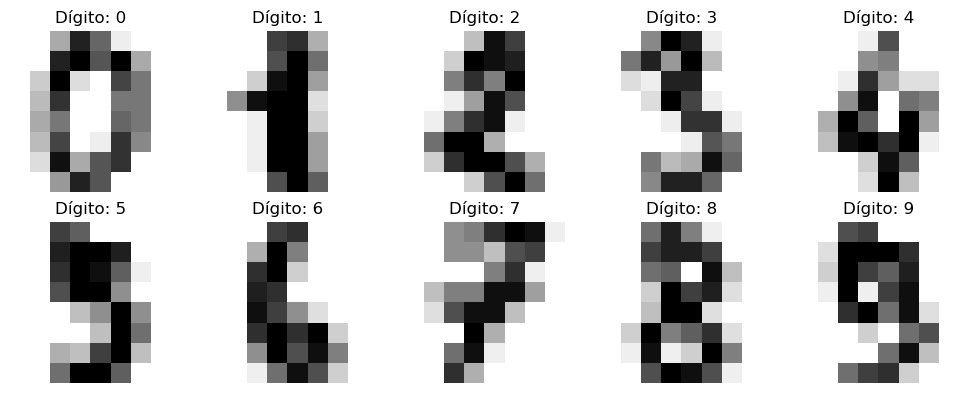

In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(
        digits.images[i],
        cmap="gray_r"
    )
    ax.set_title(f"Dígito: {y[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### Parte 2. Entrenamiento de una SVM multiclase
Divide los datos en entrenamiento (70 %) y prueba (30 %), utilizando stratify=y y random_state=42.

Construye un Pipeline que incluya:

StandardScaler().
SVC(kernel="linear", C=1).
Entrena el modelo y evalúa su exactitud sobre los conjuntos de entrenamiento y prueba.

Preguntas:

¿Qué exactitud obtuviste en entrenamiento y prueba?

RESPUESTA: de 0.97 y 0.97

¿Cuántos clasificadores binarios entrena internamente SVC para este problema?

64(63)/2 = 2016

¿Por qué no necesitamos construir manualmente un clasificador para cada par de dígitos?

porque ya lo toma en cuenta el dataframe

In [22]:


modelo = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel = "linear", C =1))
    ]
)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.3,
                                                random_state = 42,
                                                stratify=y)

cv = StratifiedKFold(n_splits=5, shuffle = True, random_state = 42)

score = cross_val_score(modelo,X_train,y_train, cv = cv, scoring = "accuracy") 
print(f"Promedio del score",score.mean())
modelo.fit(X_train,y_train)
pred = modelo.predict(X_test)
test_ac = accuracy_score(y_test,pred)
print("Accuracy de prueba ",test_ac)



Promedio del score 0.9761272370834124
Accuracy de prueba  0.9796296296296296


## Parte 3. Comparación con un kernel RBF
Construye una segunda SVM utilizando un kernel RBF.

Utiliza inicialmente:

SVC(
    kernel="rbf",
    C=1,
    gamma="scale"
)

Compara su desempeño con el modelo lineal.

Preguntas:

¿Qué modelo obtuvo mayor exactitud en el conjunto de prueba?

Si.

¿Existe una diferencia importante entre ambos resultados?

No.

¿Qué ventaja podría ofrecer un kernel RBF para reconocer dígitos escritos a mano?

Que no necesariamente las calse de separación sean linealis

¿Podemos concluir que el modelo más complejo siempre será mejor?

No.

In [23]:


modelo = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel = "rbf", C =1,gamma = 'scale'))
    ]
)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.3,
                                                random_state = 42,
                                                stratify=y)

cv = StratifiedKFold(n_splits=5, shuffle = True, random_state = 42)

score = cross_val_score(modelo,X_train,y_train, cv = cv, scoring = "accuracy") 
print(f"Promedio del score",score.mean())
modelo.fit(X_train,y_train)
pred = modelo.predict(X_test)
test_ac = accuracy_score(y_test,pred)
print("Accuracy de prueba ",test_ac)



Promedio del score 0.9745399354961108
Accuracy de prueba  0.9833333333333333


### Parte 4. Selección de hiperparámetros
Utiliza GridSearchCV para seleccionar los hiperparámetros de la SVM con kernel RBF.

Considera:


y


Utiliza validación cruzada estratificada de 3 pliegues y accuracy como métrica de evaluación.

Realiza la búsqueda únicamente sobre los datos de entrenamiento y utiliza n_jobs=2 para limitar el paralelismo.

Preguntas:

¿Cuántas combinaciones de hiperparámetros se evaluarán?

RESPUESTA: 9

¿Cuántos ajustes se realizarán durante la validación cruzada?

RESPUESTA: 27

¿Qué combinación de 
 y 
 obtuvo el mejor desempeño promedio?

RESPUESTA: C=10 y gamma = 0.01

¿La búsqueda mejoró el resultado obtenido inicialmente con el kernel RBF?

RESPUESTA: No tanto.

¿El mejor modelo supera a la SVM lineal?

Respuesta: Igual no tanto.

In [24]:
param_grid = {
    "svc__C": [1,10,100],
    "svc__gamma": [0.001,0.01,0.1]
}

cv = StratifiedKFold(n_splits=3, shuffle = True, random_state = 42)

modelo = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel = "rbf"))
    ]
)


grid_search = GridSearchCV(
    estimator=modelo,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=2,
    return_train_score=True
)


grid_search.fit(X_train, y_train)
print(grid_search.best_params_)
print("Accuracy de entrenamiento promedio: ",grid_search.cv_results_["mean_train_score"].mean() )
print("Accuracy de testeo promedio: ",grid_search.cv_results_["mean_test_score"].mean() )
print("Accuracy validacion: ",grid_search.best_score_)
print("Accuracy de prueba: ",accuracy_score(y_test,grid_search.predict(X_test)))

{'svc__C': 10, 'svc__gamma': 0.01}
Accuracy de entrenamiento promedio:  0.9926191107575355
Accuracy de testeo promedio:  0.9482011844780343
Accuracy validacion:  0.973747016706444
Accuracy de prueba:  0.9814814814814815


### Parte 5. ¿Qué dígitos son más difíciles de clasificar?
Utiliza el mejor modelo obtenido y calcula la matriz de confusión sobre el conjunto de prueba.

Puedes apoyarte en:

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    mejor_modelo,
    X_test,
    y_test,
    cmap="Blues"
)

plt.show()

Preguntas:


¿Qué dígitos se clasifican correctamente con mayor frecuencia?

RESPUESTA: Numeros cuya forma de escribir no es muy complicada

¿Qué pares de dígitos se confunden más?

el 8 con el 9 y el 9 con el 7 y el 8

¿Por qué algunos dígitos podrían resultar más difíciles de distinguir?

Porque son mas "dificiles" de reconocer en el sentido de tener una forma mas intrincada.

¿Qué información adicional proporciona la matriz de confusión que no 
podemos obtener únicamente con accuracy?

Con que numero se equivoco.

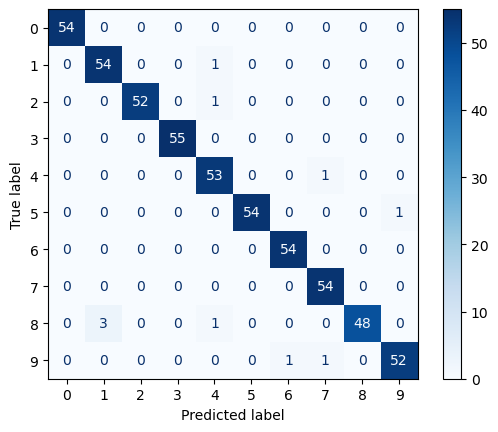

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay

mejor_modelo = grid_search.best_estimator_
ConfusionMatrixDisplay.from_estimator(
    mejor_modelo,
    X_test,
    y_test,
    cmap="Blues"
)


### Conclusiones
En este reto utilizamos una SVM para resolver un problema con diez clases y 64 variables predictoras.

Redacta una conclusión breve que responda:

¿Qué aprendiste sobre el uso de SVM en problemas multiclase?

Que son bastante utiles al momento de predecir clases.

¿Fue necesario utilizar un kernel no lineal para obtener un buen desempeño?

No necesariamente, ya que es posible que de una un hiperplano baste para clasificar una clase si asi se comporta el conjunto de datos

¿Qué modelo seleccionarías considerando tanto la exactitud como la complejidad?

Un modelo base de kernel lineal y si no funciona uno de kernel radial

Justifica tus respuestas utilizando los resultados obtenidos.